# Input patches on the cortical sheet

This notebook trains Khona, Chandra et al.'s (2023) locality-masked RNN (LM-RNN) on the 82 Mod-Cog tasks, then changes **one thing**: where the inputs land on the sheet.

- **`baseline`** (Khona's setup): every input connects to all 2500 units.
- **`patches`**: each input group (fixation, ring 1, ring 2, rule) connects only to its own patch of the sheet. Inside the patch the connection is dense. The other 77% of the sheet gets input only through local recurrence.

Everything else is identical: the same seed, data stream, recurrent mask, readout and optimizer. Training ran separately with `python -m cortical.train --condition {baseline,patches} --seed 0`, and this notebook only loads `results/02_input_patches/`. The design is in `docs/superpowers/specs/2026-10-19-input-patches-design.md`.

## Setup

Khona et al. released no training code. Each setting below is marked as stated in the paper, inferred from the paper's parameter counts, or chosen by us.

| setting | value | source |
|---|---|---|
| tasks | Mod-Cog, 82 tasks, interleaved at random; one-hot rule input (115 inputs, 17 outputs) | paper |
| dynamics | `h_{t+1} = relu(W h_t + W_in u_t + b_ih + b_hh)`, `o = W_out h + b_out` | paper (equation); inferred (two biases); chosen (ReLU) |
| sheet | 50×50 = 2500 units on a torus | paper; inferred (periodic boundaries) |
| recurrent mask | torus distance ≤ 6, self-connections included: 282,500 weights (4.5%) | paper; the counts match exactly |
| readout | dense | paper |
| init | PyTorch `nn.RNN` / `nn.Linear` defaults | inferred |
| training | Adam with lr 1e-3; unweighted cross-entropy at every step; batch 4 × 350 steps; 10k gradient steps | paper; batch and sequence length from the Mod-Cog README |
| seeds | 1 per condition | chosen (the paper used 15) |
| metric | a trial is correct only if the network holds fixation until the response period and outputs the target at every response step; 32 trials per task on a fixed evaluation set | chosen |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Rectangle

from cortical.sheet import locality_mask
from cortical.wiring import INPUT_GROUPS, LAYOUT_B, input_mask

RESULTS = Path("../results/02_input_patches")
CONDITIONS = ("baseline", "patches")
L, D = 50, 6

SURFACE, INK, MUTED, RULE = "#fcfcfb", "#0b0b0b", "#52514e", "#c3c2b7"
CONDITION_COLORS = {"baseline": "#2a78d6", "patches": "#eb6834"}  # categorical slots 1, 2
GROUP_COLORS = {"fixation": "#8a8a86", "ring1": "#1baf7a", "ring2": "#6250d6", "rule": "#eda100"}
FAMILIES = ("base", "int", "seq")
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "text.color": INK,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.edgecolor": RULE,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
    }
)

runs = {c: json.loads((RESULTS / f"{c}_s0" / "metrics.json").read_text()) for c in CONDITIONS}
for condition, run in runs.items():
    last = run["evals"][-1]["step"]
    status = "done" if run["done"] else f"IN PROGRESS (last eval at step {last})"
    print(f"{condition:9s} {status}")

baseline  done
patches   done


## Wiring

The left panel shows the sheet under `patches`. Each input group drives only its square. The circle marks the reach of one unit's recurrent connections (radius 6). The patch centres sit on a 2×2 lattice 25 units apart, with the two rings at opposite corners. The sheet wraps around, so the rings are 35 units apart, as far apart as the torus allows, and rule and fixation each neighbour both rings. Activity spreads at most 6 units per 100 ms step, so ring 1 needs at least 4–6 steps to reach ring 2.

The right panel shows the input mask itself: 115 inputs × 2500 units. Units run in row-major order, so each patch shows up as a set of stripes.

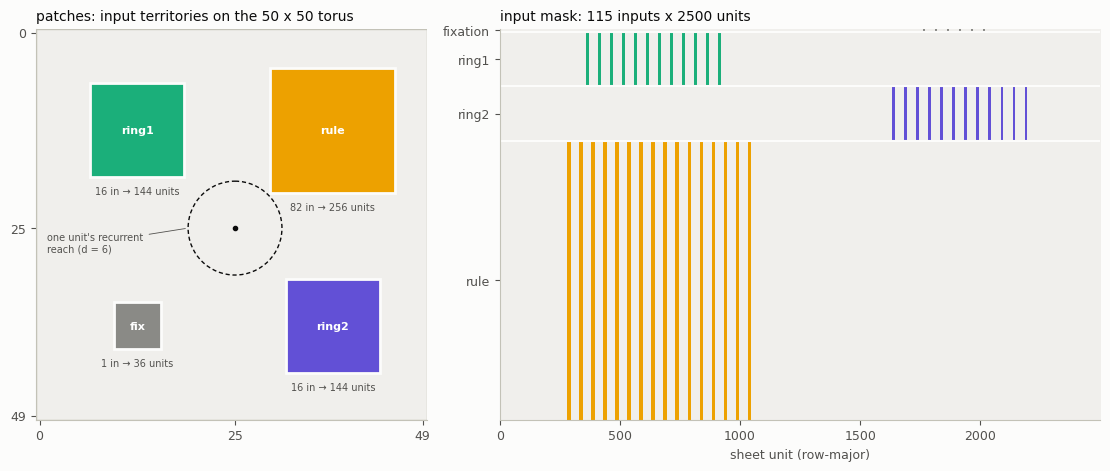

baseline  input weights 287,500   recurrent weights 282,500   (mask: 282,500)
patches   input weights  25,636   recurrent weights 282,500   (mask: 282,500)


In [2]:
fig, (ax_map, ax_mask) = plt.subplots(
    1, 2, figsize=(11, 4.6), width_ratios=[1, 1.5], layout="constrained"
)

ax_map.set_xlim(-0.5, L - 0.5)
ax_map.set_ylim(L - 0.5, -0.5)
ax_map.set_aspect("equal")
ax_map.add_patch(Rectangle((-0.5, -0.5), L, L, facecolor="#f0efec", edgecolor=RULE))
for group, (centre, size) in LAYOUT_B.items():
    x0, y0 = centre[0] - size / 2, centre[1] - size / 2
    ax_map.add_patch(
        Rectangle((x0, y0), size, size, facecolor=GROUP_COLORS[group], edgecolor=SURFACE, lw=2)
    )
    n_inputs = INPUT_GROUPS[group].stop - INPUT_GROUPS[group].start
    name = group if size >= 10 else "fix"  # the 6x6 fixation patch is too small for the full name
    ax_map.text(
        *centre, name, ha="center", va="center", fontsize=8, color="white", fontweight="bold"
    )
    caption = f"{n_inputs} in → {size * size} units"
    ax_map.text(centre[0], y0 + size + 1.2, caption, ha="center", va="top", fontsize=7, color=MUTED)
ax_map.add_patch(Circle((25, 25), D, facecolor="none", edgecolor=INK, lw=1, ls=(0, (3, 2))))
ax_map.plot(25, 25, marker="o", ms=3, color=INK)
ax_map.annotate(
    "one unit's recurrent\nreach (d = 6)",
    (25 - D, 25),
    (1, 28),
    fontsize=7,
    color=MUTED,
    arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.6},
)
ax_map.set_title("patches: input territories on the 50 x 50 torus", loc="left", fontsize=10)
ax_map.set_xticks([0, 25, 49])
ax_map.set_yticks([0, 25, 49])

mask = input_mask(L, LAYOUT_B)
group_index = np.zeros(mask.shape, dtype=int)
for i, rows in enumerate(INPUT_GROUPS.values(), start=1):
    group_index[rows] = np.where(mask[rows], i, 0)
cmap = ListedColormap(["#f0efec", *GROUP_COLORS.values()])
ax_mask.imshow(group_index, aspect="auto", cmap=cmap, vmin=0, vmax=4, interpolation="nearest")
ax_mask.set_yticks([(s.start + s.stop - 1) / 2 for s in INPUT_GROUPS.values()], list(INPUT_GROUPS))
for s in list(INPUT_GROUPS.values())[1:]:
    ax_mask.axhline(s.start - 0.5, color=SURFACE, lw=1.5)
ax_mask.set_xlabel("sheet unit (row-major)")
ax_mask.set_title("input mask: 115 inputs x 2500 units", loc="left", fontsize=10)
plt.show()

rec = int(locality_mask(L, D).sum())
for condition in CONDITIONS:
    cfg = runs[condition]["config"]
    n_in, n_rec = cfg["n_input_weights"], cfg["n_recurrent_weights"]
    print(
        f"{condition:9s} input weights {n_in:>7,}   recurrent weights {n_rec:>7,}   (mask: {rec:,})"
    )

## Learning curves

Training loss is smoothed over 100 steps. Accuracy is measured on the fixed evaluation set every 500 steps, both overall and per family:
- **base**: Cog20, 20 tasks
- **int**: interval estimation, 22 tasks
- **seq**: sequence generation, 40 tasks

The table in Khona et al. reports overall accuracy at 10k steps. It is about 0.80 for this LM-RNN, under their (unpublished) metric.

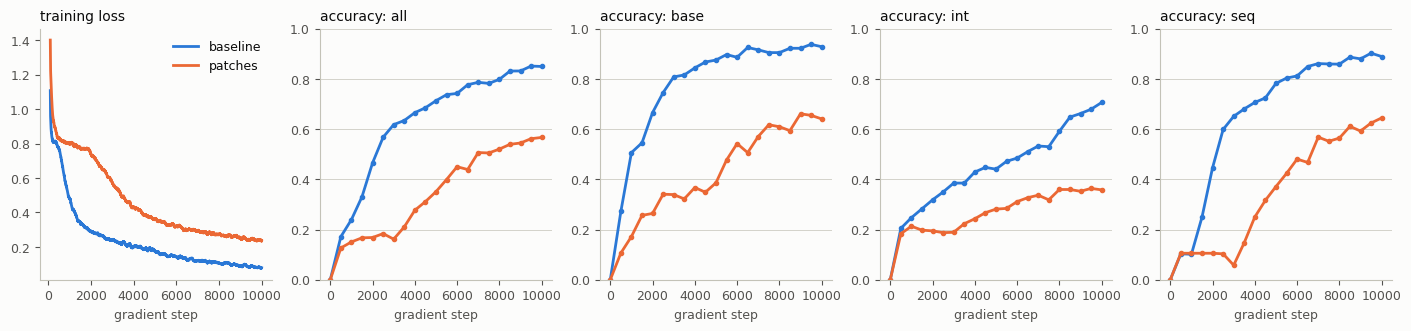

In [3]:
def smooth(steps, values, window=100):
    """Moving average; returns the steps each window ends at and the window means."""
    window = min(window, len(values))
    kernel = np.ones(window) / window
    return steps[window - 1 :], np.convolve(values, kernel, mode="valid")


fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), layout="constrained")
for condition, run in runs.items():
    color = CONDITION_COLORS[condition]
    steps, loss = np.array(run["loss"]).T
    axes[0].plot(*smooth(steps, loss), color=color, lw=2, label=condition)
    eval_steps = [e["step"] for e in run["evals"]]
    for ax, key in zip(axes[1:], ("all", *FAMILIES), strict=True):
        ax.plot(
            eval_steps,
            [e["summary"][key] for e in run["evals"]],
            color=color,
            lw=2,
            marker="o",
            ms=3,
        )
axes[0].set_title("training loss", loc="left", fontsize=10)
axes[0].legend(frameon=False)
for ax, key in zip(axes[1:], ("all", *FAMILIES), strict=True):
    ax.set_title(f"accuracy: {key}", loc="left", fontsize=10)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", color=RULE, lw=0.5)
for ax in axes:
    ax.set_xlabel("gradient step")
plt.show()

## Final performance per task

Each row is one task, scored on its 32 evaluation trials at the last evaluation. The tasks are grouped by family, and a line joins each task's two conditions. Where only an orange dot shows, the two conditions tie.

The match tasks (`dms`, `dnms`, `dmc`, `dnmc` and their variants) sit near 0.5 even for a network that only fixates. Half of their trials are no-go trials, and fixating is the correct answer on those.

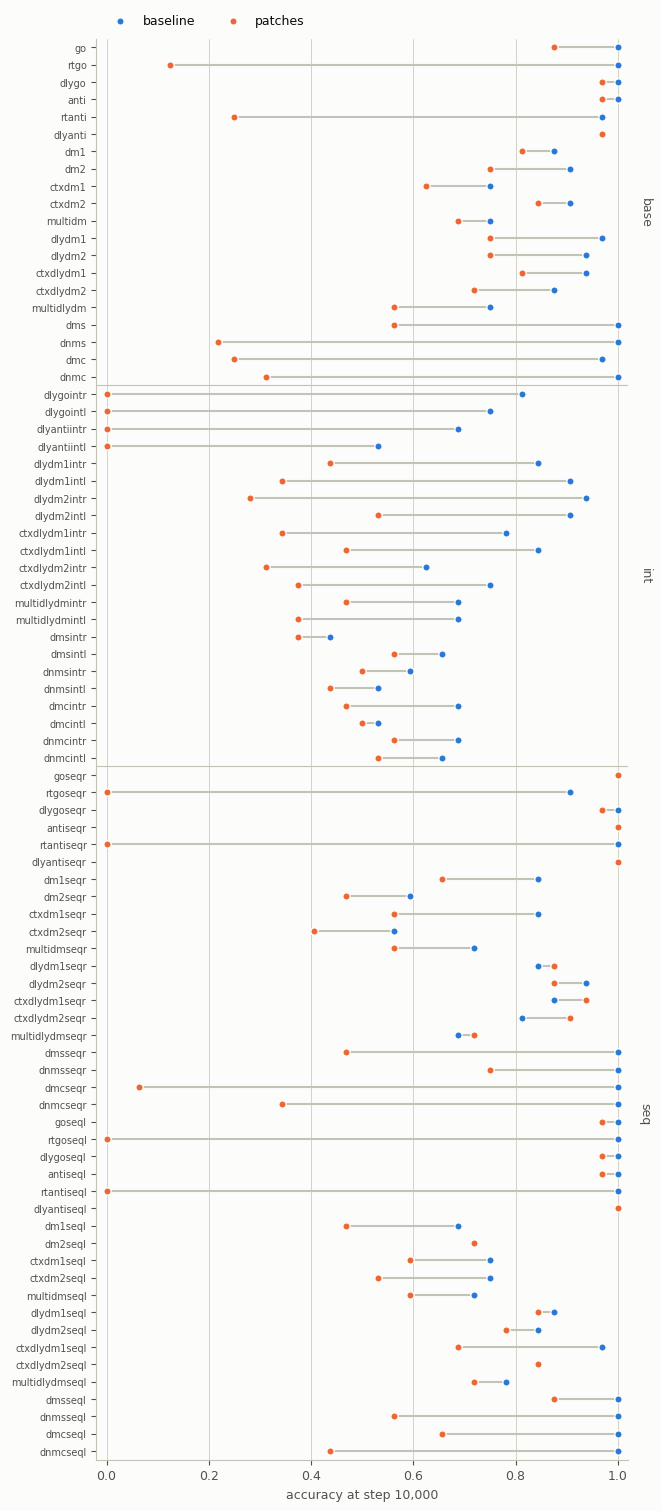

               all    base     int     seq
baseline     0.849   0.928   0.706   0.889
patches      0.567   0.641   0.358   0.645
Δ patches   -0.283  -0.287  -0.348  -0.245


In [4]:
final = {c: run["evals"][-1] for c, run in runs.items()}
tasks = list(final["baseline"]["acc"])


def family(task):
    if task.endswith(("seqr", "seql")):
        return "seq"
    return "int" if task.endswith(("intr", "intl")) else "base"


ordered = [t for fam in FAMILIES for t in tasks if family(t) == fam]
y = np.arange(len(ordered))
fig, ax = plt.subplots(figsize=(6.5, 15), layout="constrained")
base_acc = np.array([final["baseline"]["acc"][t] for t in ordered])
patch_acc = np.array([final["patches"]["acc"][t] for t in ordered])
ax.hlines(y, np.minimum(base_acc, patch_acc), np.maximum(base_acc, patch_acc), color=RULE, lw=1.5)
for condition, acc in (("baseline", base_acc), ("patches", patch_acc)):
    ax.scatter(
        acc,
        y,
        s=28,
        color=CONDITION_COLORS[condition],
        edgecolor=SURFACE,
        lw=1,
        zorder=3,
        label=condition,
    )
boundary = 0
for fam in FAMILIES:
    n = sum(family(t) == fam for t in ordered)
    ax.text(
        1.02,
        boundary + n / 2 - 0.5,
        fam,
        rotation=-90,
        va="center",
        color=MUTED,
        transform=ax.get_yaxis_transform(),
    )
    boundary += n
    if boundary < len(ordered):
        ax.axhline(boundary - 0.5, color=RULE, lw=0.8)
ax.set_yticks(y, ordered, fontsize=7)
ax.set_ylim(len(ordered) - 0.5, -0.5)
ax.set_xlim(-0.02, 1.02)
ax.set_xlabel(f"accuracy at step {final['baseline']['step']:,}")
ax.grid(axis="x", color=RULE, lw=0.5)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, frameon=False)
plt.show()

print(f"{'':10s}" + "".join(f"{k:>8s}" for k in ("all", *FAMILIES)))
for condition in CONDITIONS:
    summary = final[condition]["summary"]
    print(f"{condition:10s}" + "".join(f"{summary[k]:8.3f}" for k in ("all", *FAMILIES)))
diff = {
    k: final["patches"]["summary"][k] - final["baseline"]["summary"][k] for k in ("all", *FAMILIES)
}
print(f"{'Δ patches':10s}" + "".join(f"{diff[k]:+8.3f}" for k in ("all", *FAMILIES)))

## What we see (seed 0)

- **Overall.** `baseline` reaches 0.85 at 10k steps, in line with Khona et al.'s ≈0.80 for this LM-RNN. `patches` reaches 0.57, a level `baseline` had already passed by step 2,500, and it is lower in every family: base −0.29, int −0.35, seq −0.25. Patches matches or beats baseline on 11 of the 82 tasks; 7 of those are ties at perfect or near-perfect scores. The four it wins outright are delayed-decision sequence tasks (`dlydm1seqr`, `ctxdlydm1seqr`, `ctxdlydm2seqr`, `multidlydmseqr`).
- **Reaction-time tasks fail almost completely** (mean 0.98 → 0.06 over the 6 `rt*` tasks). In these tasks the response must begin on the step the stimulus first appears. Under `patches`, the stimulus reaches only its ring patch, and the rule patch is 25 units (≥ 4 recurrent steps) away, so nothing on the sheet can combine the two within that step.
- **Interval estimation on go/anti fails** (`dlygoint*`, `dlyantiint*`: 0.53–0.81 → 0.0). The other `int` tasks degrade but are not abolished.
- **Match tasks drop toward their no-go floor** (mean 0.84 → 0.47 over the 20 dms/dnms/dmc/dnmc tasks). In this family the network can score ~0.5 just by fixating.
- **Non-reaction go/anti tasks are almost untouched** (12 tasks including their `seq` variants: 1.00 → 0.97). Here the stimulus and the rule have time to meet through recurrence before the response.

The reaction-time explanation is a hypothesis, not a test. Direct checks would be: lengthening the reaction-time window, moving the rule patch next to the rings, and measuring when stimulus information first reaches the units that drive the response. All numbers come from one seed per condition.

## Caveat

There is **one seed per condition**. In Khona et al., the seed-to-seed spread at 10k steps is about ±0.01 (mean ± s.e.m. over 15 seeds), and our strict metric may be noisier per task: 32 trials give a per-task standard error of up to ±0.09. Treat any differences here as preliminary until they replicate across seeds.